# SAMS Vision — Safe / Unsafe Behaviour Training

Train and compare **vision classifiers** for workplace safe vs unsafe behaviours using the
[Voxel51/Safe_and_Unsafe_Behaviours](https://huggingface.co/datasets/Voxel51/Safe_and_Unsafe_Behaviours) dataset.

## Goals
- Load & inspect the vision dataset first (do not train blindly)
- Run a full **EDA** (splits, class imbalance, safe/unsafe mix, video stats, frame gallery)
- Run **≥ 5 experiments**, each with a **different approach**
- Run experiments **one at a time** (train → evaluate → save → garbage-collect → next)
- Save **weights + metadata** together
- Compare models with **Accuracy, Precision, Recall, F1-score** (macro & weighted)

## Experiment plan
| # | Approach | Model | Key idea |
|---|----------|-------|----------|
| 1 | Baseline from scratch | TinyCNN | No pretrained weights |
| 2 | Frozen transfer learning | ResNet18 | ImageNet backbone frozen |
| 3 | Fine-tuning | ResNet18 | Unfreeze backbone, lower LR |
| 4 | Efficient architecture | EfficientNet-B0 | Strong ImageNet prior |
| 5 | Edge-friendly | MobileNetV3-Small | Lightweight for SAMS deployment |
| 6 | Robust training | EfficientNet-B0 + class weights + strong aug | Handle imbalance / hard cases |

## 0. Colab setup — directories, Drive, packages


In [1]:
# --- Colab environment -------------------------------------------------------
import os
from pathlib import Path

IN_COLAB = False
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

# Ephemeral workspace (fast local disk in Colab)
SAMS_ROOT = Path("/content/SAMS") if IN_COLAB else Path("./SAMS_runtime")
for p in [
    SAMS_ROOT / "datasets" / "vision" / "safe_unsafe",
    SAMS_ROOT / "datasets" / "vision" / "steelbench",
    SAMS_ROOT / "datasets" / "vision" / "worker_detection",
    SAMS_ROOT / "datasets" / "vibration" / "bosch_cnc",
    SAMS_ROOT / "datasets" / "vibration" / "accelerometer",
    SAMS_ROOT / "models",
    SAMS_ROOT / "notebooks",
    SAMS_ROOT / "results",
]:
    p.mkdir(parents=True, exist_ok=True)

print("SAMS_ROOT:", SAMS_ROOT.resolve())


Running in Colab: True
SAMS_ROOT: /content/SAMS


In [2]:
# --- Mount Google Drive (persist trained models / results) -------------------
DRIVE_ROOT = None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
    for p in [
        DRIVE_ROOT / "models" / "vision",
        DRIVE_ROOT / "experiments",
        DRIVE_ROOT / "results" / "vision",
        DRIVE_ROOT / "sams_dataset",
    ]:
        p.mkdir(parents=True, exist_ok=True)
    print("DRIVE_ROOT:", DRIVE_ROOT)
else:
    DRIVE_ROOT = Path("./SAMS_drive_mirror")
    for p in [
        DRIVE_ROOT / "models" / "vision",
        DRIVE_ROOT / "experiments",
        DRIVE_ROOT / "results" / "vision",
    ]:
        p.mkdir(parents=True, exist_ok=True)
    print("Local DRIVE_ROOT mirror:", DRIVE_ROOT.resolve())

MODELS_DIR = DRIVE_ROOT / "models" / "vision"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision"
EXPERIMENTS_DIR = DRIVE_ROOT / "experiments"
FRAMES_DIR = SAMS_ROOT / "datasets" / "vision" / "safe_unsafe" / "frames"
FRAMES_DIR.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive
DRIVE_ROOT: /content/drive/MyDrive/SAMS


In [3]:
# --- Install dependencies ----------------------------------------------------
import subprocess
import sys

pkgs = [
    "datasets",
    "huggingface_hub",
    "fiftyone",
    "ultralytics",
    "roboflow",
    "ucimlrepo",
    "torchvision",
    "scikit-learn",
    "seaborn",
    "tqdm",
    "opencv-python-headless",
]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
    print("Packages installed.")
else:
    print("Skipping pip install outside Colab (use your venv if needed).")
    print("Required:", ", ".join(pkgs))


Packages installed.


### Hugging Face auth

If downloads fail due to rate limits, add a Colab Secret named `HF_TOKEN`, then run the next cell.


In [10]:
# Optional HF login via Colab Secrets
import os

if IN_COLAB:
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
        if token:
            os.environ["HF_TOKEN"] = token
            os.environ["HUGGING_FACE_HUB_TOKEN"] = token
            from huggingface_hub import login
            login(token=token, add_to_git_credential=False)
            print("Logged into Hugging Face Hub via Colab Secret HF_TOKEN.")
        else:
            print("No HF_TOKEN secret found — continuing anonymously.")
    except Exception as e:
        print("HF auth skipped:", type(e).__name__, e)
else:
    if os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN"):
        print("Using HF token from environment.")
    else:
        print("No HF token set (ok for public datasets).")


HF auth skipped: SecretNotFoundError Secret HF_TOKEN does not exist.


## 1. Imports, device, garbage collection helpers


In [14]:
import gc
import json
import random
import time
import shutil
from datetime import datetime, timezone

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from tqdm.auto import tqdm


import PIL._typing as _pil_typing
if not hasattr(_pil_typing, "_Ink"):
    _pil_typing._Ink = str | int | tuple[int, ...]

from torchvision import models
from torchvision.transforms import v2 as transforms  # current transforms API

def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def free_memory(*objs) -> None:
    """Drop references, empty CUDA cache, run Python GC. Call between experiments."""
    for obj in objs:
        try:
            del obj
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        if hasattr(torch.cuda, "ipc_collect"):
            try:
                torch.cuda.ipc_collect()
            except Exception:
                pass
    print("[GC] memory freed")


DEVICE = get_device()
set_seed(42)
print("Device:", DEVICE)
print("Torch:", torch.__version__)
print("torchvision transforms: v2")


Device: cuda
Torch: 2.11.0+cu128
torchvision transforms: v2


## 2. Load & inspect — Safe / Unsafe Behaviours

**Do not train yet.** Inspect splits, labels, and one sample first.

The HF card is a **FiftyOne video** dataset (691 clips, 8 classes, train/test tags).
We load with FiftyOne, then extract a few frames per clip for image classification.

In [18]:
# --- Load via Hugging Face Hub  ---------------------------------
from huggingface_hub import snapshot_download

HF_REPO = "Voxel51/Safe_and_Unsafe_Behaviours"
DATASET_DIR = SAMS_ROOT / "datasets" / "vision" / "safe_unsafe" / "hf_snapshot"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

print("Downloading dataset snapshot (videos + samples.json)...")
local_dir = snapshot_download(
    repo_id=HF_REPO,
    repo_type="dataset",
    local_dir=str(DATASET_DIR),
)
DATASET_DIR = Path(local_dir)
print("Dataset dir:", DATASET_DIR)

samples_path = DATASET_DIR / "samples.json"
assert samples_path.exists(), f"Missing {samples_path}"

with open(samples_path) as f:
    samples_blob = json.load(f)

raw_samples = samples_blob["samples"] if isinstance(samples_blob, dict) else samples_blob
print("Num samples:", len(raw_samples))
print("First label:", raw_samples[0].get("ground_truth", {}).get("label"))
print("First tags:", raw_samples[0].get("tags"))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 698 files:   0%|          | 0/698 [00:00<?, ?it/s]

Dataset dir: /content/SAMS/datasets/vision/safe_unsafe/hf_snapshot
Num samples: 691
First label: Safe Walkway Violation
First tags: ['train']


In [20]:
# --- Inspect splits, classes, build meta_df ----------------------------------
rows = []
for s in raw_samples:
    gt = (s.get("ground_truth") or {}).get("label")
    tags = s.get("tags") or []
    split = "train" if "train" in tags else ("test" if "test" in tags else "unknown")
    rel = s.get("filepath")
    abs_path = str((DATASET_DIR / rel).resolve()) if rel else None
    md = s.get("metadata") or {}
    rows.append({
        "label": gt,
        "split": split,
        "filepath": abs_path,
        "relpath": rel,
        "duration": md.get("duration"),
        "fps": md.get("frame_rate"),
        "width": md.get("frame_width"),
        "height": md.get("frame_height"),
        "n_frames": md.get("total_frame_count"),
        "size_bytes": md.get("size_bytes"),
    })

meta_df = pd.DataFrame(rows)
print(meta_df.head())
print("\nSplit counts:\n", meta_df["split"].value_counts())
print("\nLabel counts:\n", meta_df["label"].value_counts())
print("\nLabel x split:\n", pd.crosstab(meta_df["label"], meta_df["split"]))

UNSAFE_CLASSES = {
    "Safe Walkway Violation",
    "Unauthorized Intervention",
    "Opened Panel Cover",
    "Carrying Overload with Forklift",
}
SAFE_CLASSES = {
    "Safe Walkway",
    "Authorized Intervention",
    "Closed Panel Cover",
    "Safe Carrying",
}

CLASS_NAMES = sorted(meta_df["label"].dropna().unique().tolist())
label_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
idx_to_label = {i: c for c, i in label_to_idx.items()}
print("\nCLASS_NAMES:", CLASS_NAMES)
print("Num classes:", len(CLASS_NAMES))

missing = meta_df["filepath"].map(lambda p: not Path(p).exists()).sum()
print("Missing video files:", int(missing))

                    label  split  \
0  Safe Walkway Violation  train   
1  Safe Walkway Violation  train   
2  Safe Walkway Violation  train   
3  Safe Walkway Violation  train   
4  Safe Walkway Violation  train   

                                            filepath           relpath  \
0  /content/SAMS/datasets/vision/safe_unsafe/hf_s...    data/0_tr1.mp4   
1  /content/SAMS/datasets/vision/safe_unsafe/hf_s...   data/0_tr10.mp4   
2  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr100.mp4   
3  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr101.mp4   
4  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr102.mp4   

    duration    fps  width  height  n_frames  size_bytes  
0  14.015304  24.83   1920    1080       348    25865947  
1  15.022151  24.83   1920    1080       373    29372683  
2   8.014499  24.83   1920    1080       199    14633315  
3   8.014499  24.83   1920    1080       199    14612449  
4   8.014499  24.83   1920    1080       19

In [21]:
# --- Optional: quick alternative load via `datasets` (metadata peek) ---------
# The native HF `datasets` loader may not unpack FiftyOne videos the same way.
# Keep this cell for exploration; primary path is FiftyOne above.
try:
    from datasets import load_dataset
    peek = load_dataset(HF_REPO, split="train", streaming=True)
    first = next(iter(peek))
    print("HF datasets streaming sample keys:", list(first.keys()))
    print({k: type(v).__name__ for k, v in first.items()})
except Exception as e:
    print("HF datasets peek skipped / failed (expected for FiftyOne-format repos):", type(e).__name__, e)


README.md:   0%|          | 0.00/8.78k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/695 [00:00<?, ?it/s]

HF datasets streaming sample keys: ['video']
{'video': 'VideoDecoder'}


## 2b. Exploratory Data Analysis (EDA)

Before training, understand **what** we have and **how balanced** it is.
This section covers:

1. Dataset overview & missing labels
2. Class distribution (8 behaviours)
3. Safe vs Unsafe binary mix
4. Train / test balance
5. Video metadata (duration, resolution, FPS) when available
6. Per-class visual gallery
7. EDA notes that later motivate class weights / augmentation (Exp 6)


In [22]:
# --- EDA 1: Overview & data quality ------------------------------------------
EDA_DIR = RESULTS_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("EDA — Dataset overview")
print("=" * 72)
print(f"Total videos:     {len(meta_df)}")
print(f"Unique labels:    {meta_df['label'].nunique()}")
print(f"Missing labels:   {meta_df['label'].isna().sum()}")
print(f"Missing paths:    {meta_df['filepath'].isna().sum()}")
print(f"Duplicate paths:  {meta_df['filepath'].duplicated().sum()}")
print(f"Unknown split:    {(meta_df['split'] == 'unknown').sum()}")
print()
print(meta_df.head(10))

# Attach binary target for EDA
eda_df = meta_df.copy()
eda_df["binary"] = eda_df["label"].map(
    lambda x: "unsafe" if x in UNSAFE_CLASSES else ("safe" if x in SAFE_CLASSES else "other")
)
eda_df["is_unsafe"] = (eda_df["binary"] == "unsafe").astype(int)

overview = {
    "n_videos": int(len(eda_df)),
    "n_labels": int(eda_df["label"].nunique()),
    "missing_labels": int(eda_df["label"].isna().sum()),
    "duplicate_paths": int(eda_df["filepath"].duplicated().sum()),
    "split_counts": eda_df["split"].value_counts().to_dict(),
    "binary_counts": eda_df["binary"].value_counts().to_dict(),
}
with open(EDA_DIR / "overview.json", "w") as f:
    json.dump(overview, f, indent=2)
print("Saved:", EDA_DIR / "overview.json")


EDA — Dataset overview
Total videos:     691
Unique labels:    8
Missing labels:   0
Missing paths:    0
Duplicate paths:  0
Unknown split:    0

                    label  split  \
0  Safe Walkway Violation  train   
1  Safe Walkway Violation  train   
2  Safe Walkway Violation  train   
3  Safe Walkway Violation  train   
4  Safe Walkway Violation  train   
5  Safe Walkway Violation  train   
6  Safe Walkway Violation  train   
7  Safe Walkway Violation  train   
8  Safe Walkway Violation  train   
9  Safe Walkway Violation  train   

                                            filepath           relpath  \
0  /content/SAMS/datasets/vision/safe_unsafe/hf_s...    data/0_tr1.mp4   
1  /content/SAMS/datasets/vision/safe_unsafe/hf_s...   data/0_tr10.mp4   
2  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr100.mp4   
3  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr101.mp4   
4  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr102.mp4   
5  /content/S

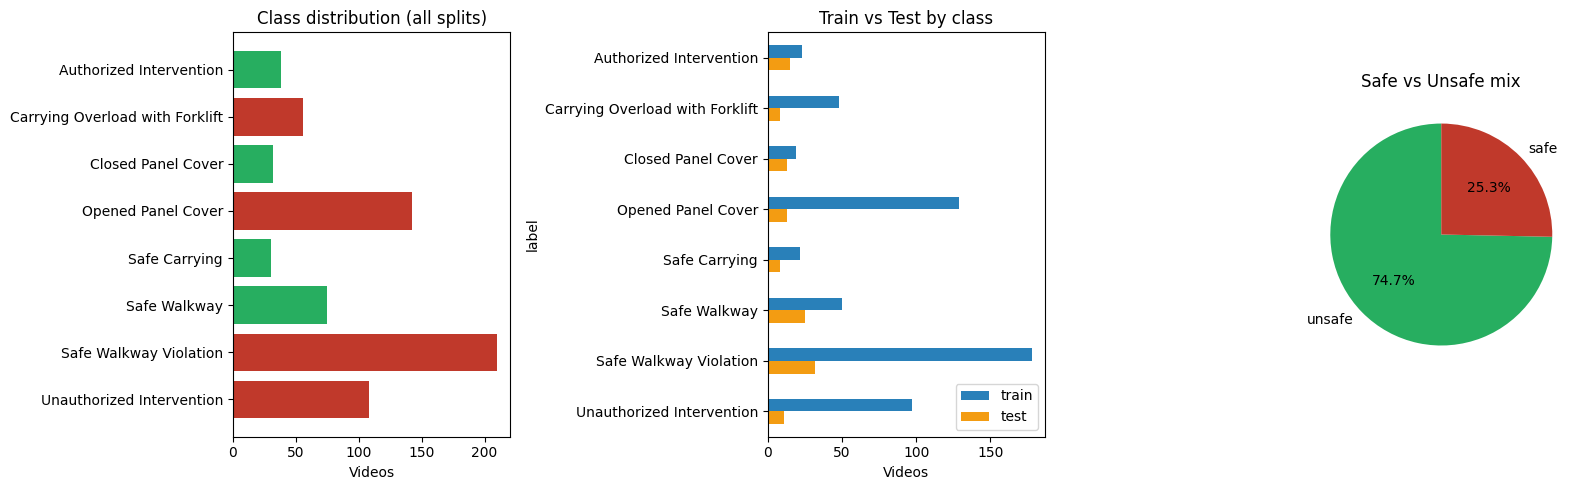

Saved: /content/drive/MyDrive/SAMS/results/vision/eda/class_distribution.png

--- Imbalance diagnostics ---
label
Safe Walkway Violation             210
Opened Panel Cover                 142
Unauthorized Intervention          108
Safe Walkway                        75
Carrying Overload with Forklift     56
Authorized Intervention             38
Closed Panel Cover                  32
Safe Carrying                       30
Name: count, dtype: int64

Max/Min class ratio: 7.00x
→ Notable imbalance — class weights / weighted sampling recommended (see Exp 6).

--- Split fractions per class ---
split                             test  train
label                                        
Authorized Intervention          0.395  0.605
Carrying Overload with Forklift  0.143  0.857
Closed Panel Cover               0.406  0.594
Opened Panel Cover               0.092  0.908
Safe Carrying                    0.267  0.733
Safe Walkway                     0.333  0.667
Safe Walkway Violation           0.1

In [23]:
# --- EDA 2: Class distribution + Safe/Unsafe mix -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (a) Overall class counts
vc = eda_df["label"].value_counts().reindex(CLASS_NAMES)
colors = ["#c0392b" if c in UNSAFE_CLASSES else "#27ae60" for c in vc.index]
axes[0].barh(vc.index, vc.values, color=colors)
axes[0].set_title("Class distribution (all splits)")
axes[0].set_xlabel("Videos")
axes[0].invert_yaxis()

# (b) Train vs test per class
ct = pd.crosstab(eda_df["label"], eda_df["split"]).reindex(CLASS_NAMES)
ct[["train", "test"]].plot(kind="barh", ax=axes[1], color=["#2980b9", "#f39c12"])
axes[1].set_title("Train vs Test by class")
axes[1].set_xlabel("Videos")
axes[1].invert_yaxis()
axes[1].legend(loc="lower right")

# (c) Binary safe / unsafe
bin_counts = eda_df["binary"].value_counts()
axes[2].pie(
    bin_counts.values,
    labels=bin_counts.index,
    autopct="%1.1f%%",
    colors=["#27ae60", "#c0392b"][: len(bin_counts)],
    startangle=90,
)
axes[2].set_title("Safe vs Unsafe mix")

plt.tight_layout()
fig_path = EDA_DIR / "class_distribution.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)

# Imbalance diagnostics
print("\n--- Imbalance diagnostics ---")
cls_counts = eda_df["label"].value_counts()
print(cls_counts)
imbalance_ratio = float(cls_counts.max() / max(cls_counts.min(), 1))
print(f"\nMax/Min class ratio: {imbalance_ratio:.2f}x")
if imbalance_ratio >= 2.0:
    print("→ Notable imbalance — class weights / weighted sampling recommended (see Exp 6).")
else:
    print("→ Mild imbalance — standard CE loss is a reasonable starting point.")

# Split fractions
print("\n--- Split fractions per class ---")
split_frac = pd.crosstab(eda_df["label"], eda_df["split"], normalize="index")
print(split_frac.round(3))
split_frac.to_csv(EDA_DIR / "split_fractions_per_class.csv")
cls_counts.to_csv(EDA_DIR / "class_counts.csv")


Videos with duration metadata: 691 / 691


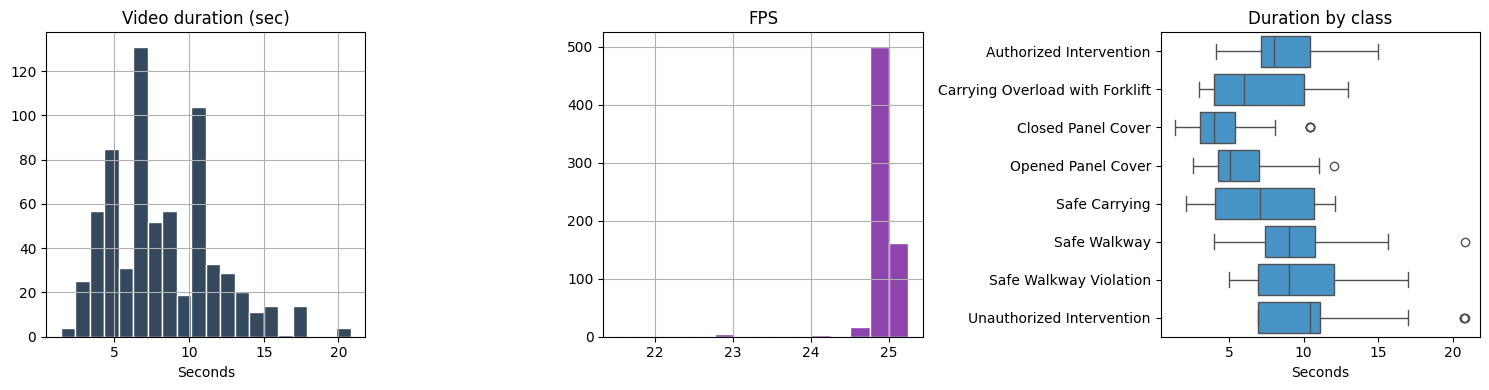

Saved: /content/drive/MyDrive/SAMS/results/vision/eda/video_metadata.png
         duration         fps   width  height    n_frames
count  691.000000  691.000000   691.0   691.0  691.000000
mean     8.403610   24.886602  1920.0  1080.0  208.950796
std      3.490564    0.268155     0.0     0.0   86.482941
min      1.393867   21.525697  1920.0  1080.0   35.000000
25%      5.988024   24.830000  1920.0  1080.0  150.000000
50%      7.971303   24.920000  1920.0  1080.0  198.000000
75%     10.450285   25.000000  1920.0  1080.0  261.000000
max     20.838323   25.252158  1920.0  1080.0  522.000000


In [25]:
# --- EDA 3: Video metadata (duration / resolution / FPS) ---------------------
video_meta = meta_df.copy()
has_duration = video_meta["duration"].notna().sum()
print(f"Videos with duration metadata: {has_duration} / {len(video_meta)}")

if has_duration > 0:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    video_meta["duration"].dropna().hist(ax=axes[0], bins=20, color="#34495e", edgecolor="white")
    axes[0].set_title("Video duration (sec)")
    axes[0].set_xlabel("Seconds")

    if video_meta["fps"].notna().any():
        video_meta["fps"].dropna().hist(ax=axes[1], bins=15, color="#8e44ad", edgecolor="white")
        axes[1].set_title("FPS")
    else:
        axes[1].text(0.5, 0.5, "FPS unavailable", ha="center", va="center")
        axes[1].set_axis_off()

    order = CLASS_NAMES
    plot_df = video_meta.dropna(subset=["duration", "label"])
    if len(plot_df):
        sns.boxplot(data=plot_df, y="label", x="duration", order=order, ax=axes[2], color="#3498db")
        axes[2].set_title("Duration by class")
        axes[2].set_xlabel("Seconds")
        axes[2].set_ylabel("")

    plt.tight_layout()
    fig_path = EDA_DIR / "video_metadata.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", fig_path)
    print(video_meta[["duration", "fps", "width", "height", "n_frames"]].describe())
else:
    print("No embedded metadata — probing a sample with OpenCV...")
    sample_paths = eda_df["filepath"].dropna().sample(n=min(40, len(eda_df)), random_state=42)
    probed = []
    for vp in sample_paths:
        cap = cv2.VideoCapture(vp)
        if not cap.isOpened():
            continue
        fps = cap.get(cv2.CAP_PROP_FPS) or None
        n = cap.get(cv2.CAP_PROP_FRAME_COUNT) or None
        w = cap.get(cv2.CAP_PROP_FRAME_WIDTH) or None
        h = cap.get(cv2.CAP_PROP_FRAME_HEIGHT) or None
        dur = (n / fps) if fps and n and fps > 0 else None
        probed.append({"filepath": vp, "fps": fps, "n_frames": n, "width": w, "height": h, "duration": dur})
        cap.release()
    probed_df = pd.DataFrame(probed)
    print(probed_df.describe())
    if len(probed_df):
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        probed_df["duration"].dropna().hist(ax=axes[0], bins=12, color="#34495e", edgecolor="white")
        axes[0].set_title("Sampled video duration (sec)")
        axes[1].scatter(probed_df["width"], probed_df["height"], alpha=0.7)
        axes[1].set_title("Resolution (sample)")
        axes[1].set_xlabel("width")
        axes[1].set_ylabel("height")
        plt.tight_layout()
        fig_path = EDA_DIR / "video_metadata_sample.png"
        plt.savefig(fig_path, dpi=150, bbox_inches="tight")
        plt.show()
        print("Saved:", fig_path)

video_meta.to_csv(EDA_DIR / "video_metadata_table.csv", index=False)

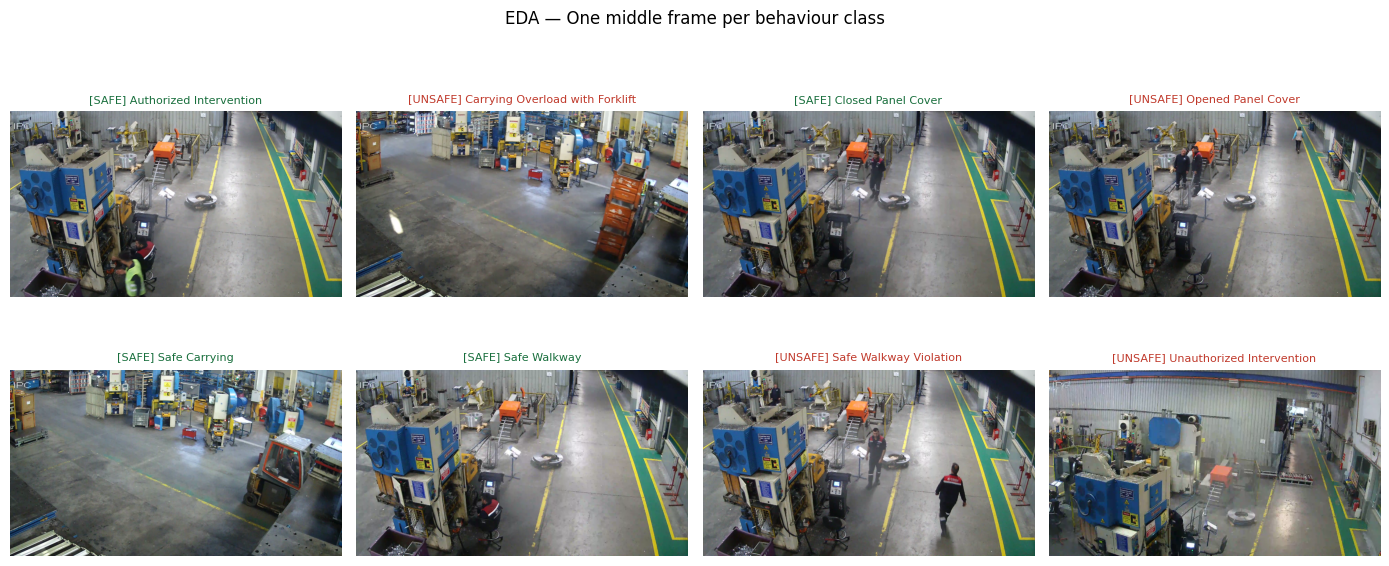

Saved: /content/drive/MyDrive/SAMS/results/vision/eda/per_class_gallery.png


In [26]:
# --- EDA 4: Per-class visual gallery (1 middle frame each) -------------------
def middle_frame_bgr(video_path: str):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return None
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    if total > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, total // 2)
    ok, frame = cap.read()
    cap.release()
    return frame if ok else None


n_classes = len(CLASS_NAMES)
cols = 4
rows = int(np.ceil(n_classes / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3.2 * rows))
axes = np.array(axes).reshape(-1)

for ax, cls in zip(axes, CLASS_NAMES):
    subset = eda_df[eda_df["label"] == cls]
    if subset.empty:
        ax.set_title(cls[:30] + " (empty)")
        ax.axis("off")
        continue
    path = subset.sample(1, random_state=42).iloc[0]["filepath"]
    frame = middle_frame_bgr(path)
    if frame is None:
        ax.set_title(cls[:30] + " (read fail)")
        ax.axis("off")
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    ax.imshow(rgb)
    kind = "UNSAFE" if cls in UNSAFE_CLASSES else "SAFE"
    ax.set_title(f"[{kind}] {cls}", fontsize=8, color=("#c0392b" if kind == "UNSAFE" else "#196f3d"))
    ax.axis("off")

for ax in axes[n_classes:]:
    ax.axis("off")

plt.suptitle("EDA — One middle frame per behaviour class", fontsize=12)
plt.tight_layout()
fig_path = EDA_DIR / "per_class_gallery.png"
plt.savefig(fig_path, dpi=140, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)


In [27]:
# --- EDA 5: Written summary (drives modelling choices) -----------------------
findings = {
    "n_videos": int(len(eda_df)),
    "n_classes": int(eda_df["label"].nunique()),
    "class_counts": eda_df["label"].value_counts().to_dict(),
    "binary_counts": eda_df["binary"].value_counts().to_dict(),
    "split_counts": eda_df["split"].value_counts().to_dict(),
    "imbalance_ratio_max_min": float(
        eda_df["label"].value_counts().max() / max(eda_df["label"].value_counts().min(), 1)
    ),
    "recommendations": [],
}

if findings["imbalance_ratio_max_min"] >= 2.0:
    findings["recommendations"].append(
        "Use class-weighted CrossEntropy and/or WeightedRandomSampler (Experiment 6)."
    )
else:
    findings["recommendations"].append(
        "Mild imbalance — start with unweighted CE; revisit if minority F1 lags."
    )

safe_n = findings["binary_counts"].get("safe", 0)
unsafe_n = findings["binary_counts"].get("unsafe", 0)
if safe_n and unsafe_n:
    findings["recommendations"].append(
        f"Binary mix safe={safe_n}, unsafe={unsafe_n} — also track binary alert metrics later."
    )

findings["recommendations"].append(
    "Frame-level training is a practical Colab proxy; keep video temporal models as a follow-up."
)
findings["recommendations"].append(
    "Prefer macro-F1 as primary metric so rare unsafe classes are not ignored."
)

with open(EDA_DIR / "eda_findings.json", "w") as f:
    json.dump(findings, f, indent=2)

print("=" * 72)
print("EDA FINDINGS")
print("=" * 72)
print(json.dumps(findings, indent=2))
print("\nArtifacts in:", EDA_DIR)


EDA FINDINGS
{
  "n_videos": 691,
  "n_classes": 8,
  "class_counts": {
    "Safe Walkway Violation": 210,
    "Opened Panel Cover": 142,
    "Unauthorized Intervention": 108,
    "Safe Walkway": 75,
    "Carrying Overload with Forklift": 56,
    "Authorized Intervention": 38,
    "Closed Panel Cover": 32,
    "Safe Carrying": 30
  },
  "binary_counts": {
    "unsafe": 516,
    "safe": 175
  },
  "split_counts": {
    "train": 566,
    "test": 125
  },
  "imbalance_ratio_max_min": 7.0,
  "recommendations": [
    "Use class-weighted CrossEntropy and/or WeightedRandomSampler (Experiment 6).",
    "Binary mix safe=175, unsafe=516 \u2014 also track binary alert metrics later.",
    "Frame-level training is a practical Colab proxy; keep video temporal models as a follow-up.",
    "Prefer macro-F1 as primary metric so rare unsafe classes are not ignored."
  ]
}

Artifacts in: /content/drive/MyDrive/SAMS/results/vision/eda


## 3. Frame extraction for image classification

Videos → a small set of frames per clip (middle + spaced). Saved under:

`/content/SAMS/datasets/vision/safe_unsafe/frames/{train,test}/<class>/`


In [29]:
def extract_frames(
    video_path: str,
    out_dir: Path,
    stem: str,
    max_frames: int = 4,
) -> list[Path]:
    """Extract up to `max_frames` evenly spaced frames from a video."""
    out_dir.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return []

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    if total <= 0:
        frames = []
        idx = 0
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frames.append((idx, frame))
            idx += 1
            if idx > 300:
                break
        total = len(frames)
        if total == 0:
            cap.release()
            return []
        indices = np.linspace(0, total - 1, num=min(max_frames, total), dtype=int)
        saved = []
        for j, i in enumerate(indices):
            path = out_dir / f"{stem}_f{j:02d}.jpg"
            cv2.imwrite(str(path), frames[i][1])
            saved.append(path)
        cap.release()
        return saved

    indices = np.linspace(0, total - 1, num=min(max_frames, total), dtype=int)
    saved = []
    for j, frame_idx in enumerate(indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ok, frame = cap.read()
        if not ok:
            continue
        path = out_dir / f"{stem}_f{j:02d}.jpg"
        cv2.imwrite(str(path), frame)
        saved.append(path)
    cap.release()
    return saved


MAX_FRAMES_PER_VIDEO = 3
MAX_VIDEOS_PER_SPLIT: int | None = None  # e.g. 80 for a quick pass

manifest_path = FRAMES_DIR / "manifest.csv"
force_reextract = False

if manifest_path.exists() and not force_reextract:
    frame_manifest = pd.read_csv(manifest_path)
    print("Reusing existing frame manifest:", manifest_path)
    print(frame_manifest.shape)
else:
    records = []
    for split_name in ["train", "test"]:
        subset = meta_df[meta_df["split"] == split_name]
        if MAX_VIDEOS_PER_SPLIT is not None:
            subset = subset.head(MAX_VIDEOS_PER_SPLIT)
        print(f"Extracting frames for split={split_name} (n_videos={len(subset)})...")
        for _, row in tqdm(subset.iterrows(), total=len(subset)):
            label = row["label"]
            if pd.isna(label) or not row["filepath"]:
                continue
            safe_label = str(label).replace("/", "_").replace(" ", "_")
            out_dir = FRAMES_DIR / split_name / safe_label
            stem = Path(row["filepath"]).stem
            paths = extract_frames(row["filepath"], out_dir, stem, max_frames=MAX_FRAMES_PER_VIDEO)
            for p in paths:
                records.append({
                    "filepath": str(p),
                    "split": split_name,
                    "label": label,
                    "label_idx": label_to_idx[label],
                    "binary": "unsafe" if label in UNSAFE_CLASSES else "safe",
                    "source_video": row["filepath"],
                })

    frame_manifest = pd.DataFrame(records)
    frame_manifest.to_csv(manifest_path, index=False)
    print("Saved manifest:", manifest_path)
    print(frame_manifest.groupby(["split", "label"]).size())

print(frame_manifest.head())
print("Total frames:", len(frame_manifest))

Extracting frames for split=train (n_videos=566)...


  0%|          | 0/566 [00:00<?, ?it/s]

Extracting frames for split=test (n_videos=125)...


  0%|          | 0/125 [00:00<?, ?it/s]

Saved manifest: /content/SAMS/datasets/vision/safe_unsafe/frames/manifest.csv
split  label                          
test   Authorized Intervention             45
       Carrying Overload with Forklift     24
       Closed Panel Cover                  38
       Opened Panel Cover                  39
       Safe Carrying                       24
       Safe Walkway                        73
       Safe Walkway Violation              93
       Unauthorized Intervention           33
train  Authorized Intervention             68
       Carrying Overload with Forklift    144
       Closed Panel Cover                  57
       Opened Panel Cover                 387
       Safe Carrying                       66
       Safe Walkway                       148
       Safe Walkway Violation             530
       Unauthorized Intervention          290
dtype: int64
                                            filepath  split  \
0  /content/SAMS/datasets/vision/safe_unsafe/fram...  train   
1  /cont

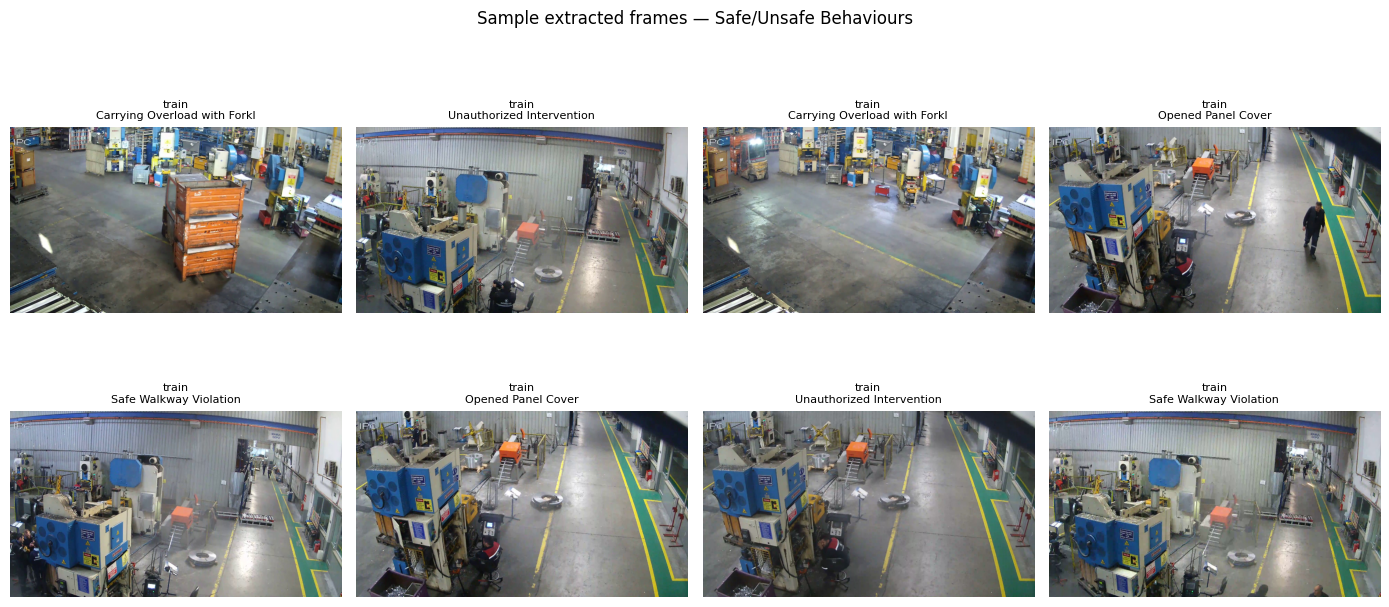

In [30]:
# --- Visualize a few extracted frames ----------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()
sample_rows = frame_manifest.sample(n=min(8, len(frame_manifest)), random_state=42)
for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    img = Image.open(row["filepath"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{row['split']}\n{row['label'][:28]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Sample extracted frames — Safe/Unsafe Behaviours")
plt.tight_layout()
plt.show()


## 3b. Frame-level EDA

After extraction: check **frame counts per class/split**, image sizes, and a stratified gallery.
Confirms the classification dataset we actually train on.


FRAME-LEVEL EDA
Total frames: 2059

Frames by split:
 split
train    1690
test      369
Name: count, dtype: int64

Frames by label:
 label
Safe Walkway Violation             623
Opened Panel Cover                 426
Unauthorized Intervention          323
Safe Walkway                       221
Carrying Overload with Forklift    168
Authorized Intervention            113
Closed Panel Cover                  95
Safe Carrying                       90
Name: count, dtype: int64

Frames by binary:
 binary
unsafe    1540
safe       519
Name: count, dtype: int64

Frames per video — describe:
count    691.000000
mean       2.979740
std        0.140992
min        2.000000
25%        3.000000
50%        3.000000
75%        3.000000
max        3.000000
dtype: float64


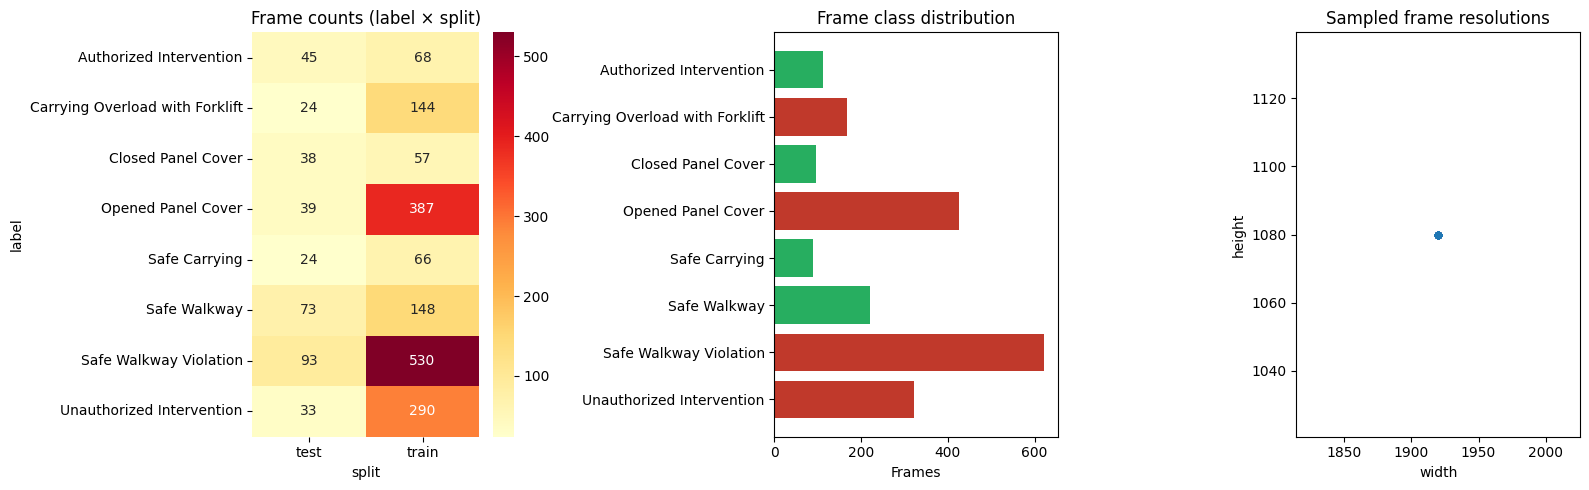

Saved: /content/drive/MyDrive/SAMS/results/vision/eda/frame_level_eda.png

Resolution describe:
         width  height        aspect
count   120.0   120.0  1.200000e+02
mean   1920.0  1080.0  1.777778e+00
std       0.0     0.0  4.013561e-15
min    1920.0  1080.0  1.777778e+00
25%    1920.0  1080.0  1.777778e+00
50%    1920.0  1080.0  1.777778e+00
75%    1920.0  1080.0  1.777778e+00
max    1920.0  1080.0  1.777778e+00


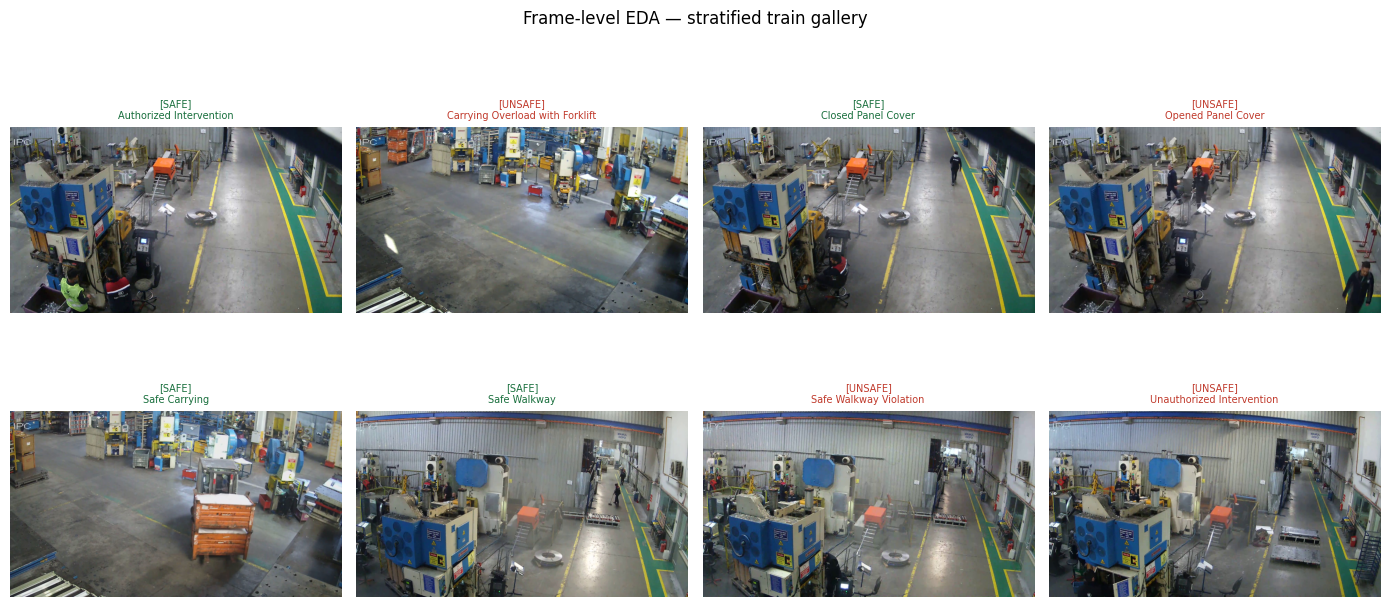

Saved: /content/drive/MyDrive/SAMS/results/vision/eda/frame_stratified_gallery.png
Frame EDA artifacts → /content/drive/MyDrive/SAMS/results/vision/eda


In [31]:
# --- Frame-level EDA ---------------------------------------------------------
assert "frame_manifest" in dir() and len(frame_manifest) > 0, "Run frame extraction first."

print("=" * 72)
print("FRAME-LEVEL EDA")
print("=" * 72)
print("Total frames:", len(frame_manifest))
print("\nFrames by split:\n", frame_manifest["split"].value_counts())
print("\nFrames by label:\n", frame_manifest["label"].value_counts())
print("\nFrames by binary:\n", frame_manifest["binary"].value_counts())

# Frames per video (approx via stem)
tmp = frame_manifest.copy()
tmp["video_stem"] = tmp["filepath"].map(lambda p: Path(p).stem.rsplit("_f", 1)[0])
frames_per_video = tmp.groupby("video_stem").size()
print("\nFrames per video — describe:")
print(frames_per_video.describe())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Class x split heatmap of frame counts
heat = pd.crosstab(frame_manifest["label"], frame_manifest["split"]).reindex(CLASS_NAMES)
sns.heatmap(heat, annot=True, fmt="d", cmap="YlOrRd", ax=axes[0])
axes[0].set_title("Frame counts (label × split)")

# Frame class distribution
fc = frame_manifest["label"].value_counts().reindex(CLASS_NAMES)
colors = ["#c0392b" if c in UNSAFE_CLASSES else "#27ae60" for c in fc.index]
axes[1].barh(fc.index, fc.values, color=colors)
axes[1].invert_yaxis()
axes[1].set_title("Frame class distribution")
axes[1].set_xlabel("Frames")

# Sample image size distribution
size_rows = []
sample_paths = frame_manifest["filepath"].sample(n=min(120, len(frame_manifest)), random_state=42)
for p in sample_paths:
    with Image.open(p) as im:
        w, h = im.size
    size_rows.append({"width": w, "height": h, "aspect": w / max(h, 1)})
size_df = pd.DataFrame(size_rows)
axes[2].scatter(size_df["width"], size_df["height"], alpha=0.55, s=18)
axes[2].set_title("Sampled frame resolutions")
axes[2].set_xlabel("width")
axes[2].set_ylabel("height")

plt.tight_layout()
fig_path = EDA_DIR / "frame_level_eda.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)
print("\nResolution describe:\n", size_df.describe())

# Stratified gallery: 1 frame per class from train
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()
for ax, cls in zip(axes, CLASS_NAMES):
    sub = frame_manifest[(frame_manifest["label"] == cls) & (frame_manifest["split"] == "train")]
    if sub.empty:
        sub = frame_manifest[frame_manifest["label"] == cls]
    if sub.empty:
        ax.axis("off")
        continue
    img = Image.open(sub.sample(1, random_state=0).iloc[0]["filepath"]).convert("RGB")
    ax.imshow(img)
    kind = "UNSAFE" if cls in UNSAFE_CLASSES else "SAFE"
    ax.set_title(f"[{kind}]\n{cls}", fontsize=7, color=("#c0392b" if kind == "UNSAFE" else "#196f3d"))
    ax.axis("off")
plt.suptitle("Frame-level EDA — stratified train gallery")
plt.tight_layout()
fig_path2 = EDA_DIR / "frame_stratified_gallery.png"
plt.savefig(fig_path2, dpi=140, bbox_inches="tight")
plt.show()
print("Saved:", fig_path2)

frame_manifest.groupby(["split", "label", "binary"]).size().rename("n").reset_index().to_csv(
    EDA_DIR / "frame_counts.csv", index=False
)
print("Frame EDA artifacts →", EDA_DIR)


## 4. Shared training utilities

One place for datasets, metrics, train loop, and **save model + metadata**.
Each experiment cell will call these, then free memory before the next.


In [32]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Stronger augmentation (used by experiment 6)
strong_train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class FrameDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        y = int(row["label_idx"])
        return img, y


def make_loaders(
    manifest: pd.DataFrame,
    train_transform=train_tfms,
    batch_size: int = BATCH_SIZE,
    use_weighted_sampler: bool = False,
) -> Tuple[DataLoader, DataLoader, pd.DataFrame, pd.DataFrame]:
    train_df = manifest[manifest["split"] == "train"].copy()
    test_df = manifest[manifest["split"] == "test"].copy()
    # Hold out 15% of train frames as validation (by video stem when possible)
    train_df["stem"] = train_df["filepath"].map(lambda p: Path(p).stem.rsplit("_f", 1)[0])
    stems = train_df["stem"].unique()
    rng = np.random.RandomState(42)
    rng.shuffle(stems)
    n_val = max(1, int(0.15 * len(stems)))
    val_stems = set(stems[:n_val])
    val_df = train_df[train_df["stem"].isin(val_stems)].drop(columns=["stem"])
    train_df = train_df[~train_df["stem"].isin(val_stems)].drop(columns=["stem"])

    train_ds = FrameDataset(train_df, transform=train_transform)
    val_ds = FrameDataset(val_df, transform=eval_tfms)
    test_ds = FrameDataset(test_df, transform=eval_tfms)

    sampler = None
    shuffle = True
    if use_weighted_sampler:
        counts = train_df["label_idx"].value_counts().to_dict()
        weights = train_df["label_idx"].map(lambda i: 1.0 / counts[i]).values
        sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
        shuffle = False

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=shuffle, sampler=sampler,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    test_loader = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    # stash loaders on a simple namespace-like dict
    return {
        "train": train_loader,
        "val": val_loader,
        "test": test_loader,
        "train_df": train_df,
        "val_df": val_df,
        "test_df": test_df,
    }


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, class_names: List[str]) -> Dict[str, Any]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_per_class": {
            class_names[i]: float(v)
            for i, v in enumerate(f1_score(y_true, y_pred, average=None, zero_division=0, labels=list(range(len(class_names)))))
        },
        "classification_report": classification_report(
            y_true, y_pred, target_names=class_names, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(range(len(class_names)))).tolist(),
    }


@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, device: torch.device, class_names: List[str]) -> Dict[str, Any]:
    model.eval()
    ys, preds = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        ys.append(y.numpy())
        preds.append(pred)
    y_true = np.concatenate(ys)
    y_pred = np.concatenate(preds)
    return compute_metrics(y_true, y_pred, class_names)


def train_one_experiment(
    model: nn.Module,
    loaders: Dict[str, Any],
    *,
    experiment_id: str,
    approach: str,
    epochs: int,
    lr: float,
    weight_decay: float = 1e-4,
    class_weights: Optional[torch.Tensor] = None,
    device: torch.device = DEVICE,
    class_names: List[str] = None,
) -> Dict[str, Any]:
    class_names = class_names or CLASS_NAMES
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device) if class_weights is not None else None)
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))

    history = {"train_loss": [], "val_loss": [], "val_f1_macro": [], "val_accuracy": []}
    best_f1 = -1.0
    best_state = None
    t0 = time.time()

    print("=" * 72)
    print(f"EXPERIMENT: {experiment_id}")
    print(f"APPROACH:   {approach}")
    print(f"Epochs={epochs}  LR={lr}  Device={device}")
    print("=" * 72)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        n = 0
        pbar = tqdm(loaders["train"], desc=f"[{experiment_id}] epoch {epoch}/{epochs}", leave=False)
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)
            n += x.size(0)
            pbar.set_postfix(loss=f"{loss.item():.4f}")
        scheduler.step()

        train_loss = running / max(n, 1)
        # val
        model.eval()
        v_running, v_n = 0.0, 0
        ys, preds = [], []
        with torch.no_grad():
            for x, y in loaders["val"]:
                x = x.to(device, non_blocking=True)
                y_dev = y.to(device, non_blocking=True)
                logits = model(x)
                loss = criterion(logits, y_dev)
                v_running += loss.item() * x.size(0)
                v_n += x.size(0)
                preds.append(logits.argmax(1).cpu().numpy())
                ys.append(y.numpy())
        val_loss = v_running / max(v_n, 1)
        y_true = np.concatenate(ys)
        y_pred = np.concatenate(preds)
        val_metrics = compute_metrics(y_true, y_pred, class_names)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1_macro"].append(val_metrics["f1_macro"])
        history["val_accuracy"].append(val_metrics["accuracy"])

        print(
            f"  epoch {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} "
            f"| val_acc={val_metrics['accuracy']:.4f} | val_f1_macro={val_metrics['f1_macro']:.4f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    test_metrics = evaluate(model, loaders["test"], device, class_names)
    elapsed = time.time() - t0

    print("\n--- Test metrics ---")
    print(f"Accuracy:          {test_metrics['accuracy']:.4f}")
    print(f"Precision (macro): {test_metrics['precision_macro']:.4f}")
    print(f"Recall (macro):    {test_metrics['recall_macro']:.4f}")
    print(f"F1 (macro):        {test_metrics['f1_macro']:.4f}")
    print(f"F1 (weighted):     {test_metrics['f1_weighted']:.4f}")
    print(test_metrics["classification_report"])

    result = {
        "experiment_id": experiment_id,
        "approach": approach,
        "epochs": epochs,
        "lr": lr,
        "weight_decay": weight_decay,
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "device": str(device),
        "elapsed_sec": elapsed,
        "class_names": class_names,
        "label_to_idx": label_to_idx,
        "best_val_f1_macro": best_f1,
        "history": history,
        "test_metrics": {k: v for k, v in test_metrics.items() if k != "classification_report"},
        "classification_report": test_metrics["classification_report"],
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "dataset": HF_REPO,
        "task": "multiclass_behaviour_classification",
        "num_classes": len(class_names),
    }
    return model, result


def save_experiment(model: nn.Module, result: Dict[str, Any], extra_meta: Optional[Dict] = None) -> Path:
    """Save weights + metadata sidecar together under Drive models/vision."""
    exp_id = result["experiment_id"]
    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)

    weights_path = out_dir / "model.pt"
    meta_path = out_dir / "metadata.json"
    history_path = out_dir / "history.json"
    report_path = out_dir / "classification_report.txt"
    cm_path = out_dir / "confusion_matrix.png"

    meta = dict(result)
    if extra_meta:
        meta.update(extra_meta)
    # Don't duplicate large blobs oddly — history saved separately
    history = meta.pop("history", {})
    report = meta.pop("classification_report", "")
    cm = np.array(meta.get("test_metrics", {}).get("confusion_matrix", []))

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "metadata": {k: v for k, v in meta.items() if k != "test_metrics"},
            "test_metrics": meta.get("test_metrics"),
            "class_names": result["class_names"],
            "label_to_idx": result["label_to_idx"],
        },
        weights_path,
    )

    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)
    with open(report_path, "w") as f:
        f.write(report)

    if cm.size:
        plt.figure(figsize=(8, 6))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=result["class_names"], yticklabels=result["class_names"],
        )
        plt.xticks(rotation=45, ha="right", fontsize=7)
        plt.yticks(fontsize=7)
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title(f"Confusion Matrix — {exp_id}")
        plt.tight_layout()
        plt.savefig(cm_path, dpi=140)
        plt.show()

    # Append to global results ledger
    ledger_path = RESULTS_DIR / "vision_experiment_ledger.csv"
    row = {
        "experiment_id": exp_id,
        "approach": result["approach"],
        "accuracy": result["test_metrics"]["accuracy"],
        "precision_macro": result["test_metrics"]["precision_macro"],
        "recall_macro": result["test_metrics"]["recall_macro"],
        "f1_macro": result["test_metrics"]["f1_macro"],
        "f1_weighted": result["test_metrics"]["f1_weighted"],
        "best_val_f1_macro": result["best_val_f1_macro"],
        "epochs": result["epochs"],
        "lr": result["lr"],
        "elapsed_sec": result["elapsed_sec"],
        "weights_path": str(weights_path),
        "metadata_path": str(meta_path),
        "timestamp_utc": result["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        # replace same experiment_id if re-run
        prev = prev[prev["experiment_id"] != exp_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)

    print(f"[SAVE] weights → {weights_path}")
    print(f"[SAVE] metadata → {meta_path}")
    print(f"[SAVE] ledger → {ledger_path}")
    return out_dir


# Registry collected in-notebook for the final comparison table
EXPERIMENT_RESULTS: List[Dict[str, Any]] = []
print("Utilities ready.")


Utilities ready.


/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


## 5. Model builders

In [33]:
class TinyCNN(nn.Module):
    """Small CNN trained from scratch — Experiment 1 baseline."""

    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet18(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model


def build_efficientnet_b0(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    model = models.efficientnet_b0(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def build_mobilenet_v3_small(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = models.mobilenet_v3_small(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


NUM_CLASSES = len(CLASS_NAMES)
print("NUM_CLASSES:", NUM_CLASSES)


NUM_CLASSES: 8


## 6. Experiments
Each block below:
1. States the **approach**
2. Builds the model
3. Trains & evaluates (Accuracy / Precision / Recall / **F1**)
4. Saves **model + metadata**
5. **Garbage-collects** before the next experiment

Adjust `EPOCHS_*` if you need a faster smoke test.


In [34]:
# Global epoch knobs — raise for serious runs
EPOCHS_BASELINE = 8
EPOCHS_TRANSFER = 6
EPOCHS_FINETUNE = 8
EPOCHS_EFFICIENT = 6
EPOCHS_MOBILE = 6
EPOCHS_ROBUST = 8

# Shared loaders (standard augmentation) — rebuilt per experiment if needed
base_loaders = make_loaders(frame_manifest, train_transform=train_tfms)
print(
    "Train/Val/Test sizes:",
    len(base_loaders["train_df"]),
    len(base_loaders["val_df"]),
    len(base_loaders["test_df"]),
)


Train/Val/Test sizes: 1438 252 369


### Experiment 1 — Baseline CNN from scratch
**Approach:** train a small CNN with random init (no ImageNet). Establishes a lower bound.


EXPERIMENT: vision_exp01_tinycnn_scratch
APPROACH:   Baseline CNN from scratch (no pretrained weights)
Epochs=8  LR=0.001  Device=cuda


[vision_exp01_tinycnn_scratch] epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.3201 | val_loss=1.2482 | val_acc=0.5357 | val_f1_macro=0.3457


[vision_exp01_tinycnn_scratch] epoch 2/8:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

[vision_exp01_tinycnn_scratch] epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 08 | train_loss=0.9588 | val_loss=1.0390 | val_acc=0.5873 | val_f1_macro=0.3542


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


--- Test metrics ---
Accuracy:          0.4390
Precision (macro): 0.3760
Recall (macro):    0.4346
F1 (macro):        0.3363
F1 (weighted):     0.3387
                                 precision    recall  f1-score   support

        Authorized Intervention       0.00      0.00      0.00        45
Carrying Overload with Forklift       0.59      1.00      0.74        24
             Closed Panel Cover       0.00      0.00      0.00        38
             Opened Panel Cover       0.22      1.00      0.36        39
                  Safe Carrying       1.00      0.29      0.45        24
                   Safe Walkway       0.00      0.00      0.00        73
         Safe Walkway Violation       0.65      0.88      0.75        93
      Unauthorized Intervention       0.56      0.30      0.39        33

                       accuracy                           0.44       369
                      macro avg       0.38      0.43      0.34       369
                   weighted avg       0.34 

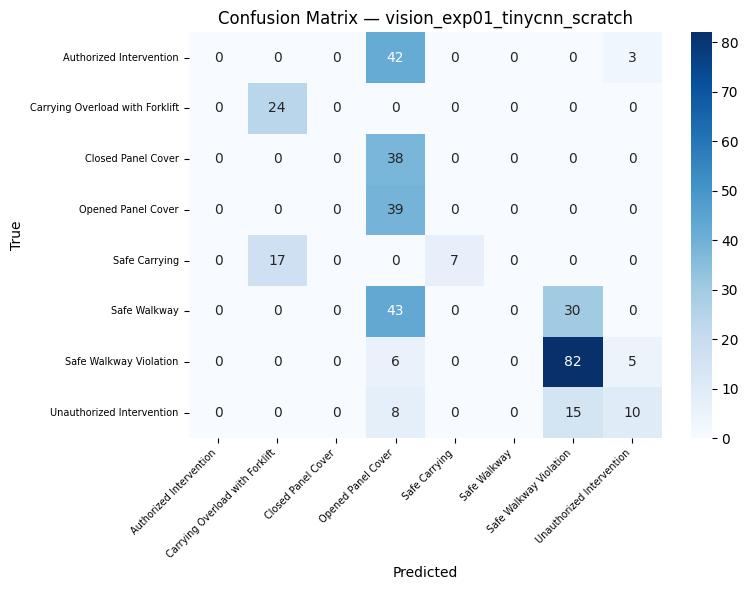

[SAVE] weights → /content/drive/MyDrive/SAMS/models/vision/vision_exp01_tinycnn_scratch/model.pt
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vision/vision_exp01_tinycnn_scratch/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vision/vision_experiment_ledger.csv
[GC] memory freed


In [35]:
exp_id = "vision_exp01_tinycnn_scratch"
approach = "Baseline CNN from scratch (no pretrained weights)"

model = TinyCNN(NUM_CLASSES)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_BASELINE,
    lr=1e-3,
)
save_experiment(model, result, extra_meta={"architecture": "TinyCNN", "pretrained": False})
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None


### Experiment 2 — ResNet18 frozen transfer learning
**Approach:** ImageNet-pretrained ResNet18, backbone frozen, train classifier head only.


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


EXPERIMENT: vision_exp02_resnet18_frozen
APPROACH:   Transfer learning — ResNet18 (frozen backbone)
Epochs=6  LR=0.001  Device=cuda


[vision_exp02_resnet18_frozen] epoch 1/6:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.4189 | val_loss=1.1308 | val_acc=0.5516 | val_f1_macro=0.3383


...

[vision_exp02_resnet18_frozen] epoch 6/6:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 06 | train_loss=0.9294 | val_loss=1.0026 | val_acc=0.6310 | val_f1_macro=0.4467


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


--- Test metrics ---
Accuracy:          0.4417
Precision (macro): 0.3756
Recall (macro):    0.4587
F1 (macro):        0.3676
F1 (weighted):     0.3521
                                 precision    recall  f1-score   support

        Authorized Intervention       0.00      0.00      0.00        45
Carrying Overload with Forklift       0.65      1.00      0.79        24
             Closed Panel Cover       0.00      0.00      0.00        38
             Opened Panel Cover       0.23      1.00      0.37        39
                  Safe Carrying       1.00      0.46      0.63        24
                   Safe Walkway       0.00      0.00      0.00        73
         Safe Walkway Violation       0.65      0.82      0.72        93
      Unauthorized Intervention       0.48      0.39      0.43        33

                       accuracy                           0.44       369
                      macro avg       0.38      0.46      0.37       369
                   weighted avg       0.34 

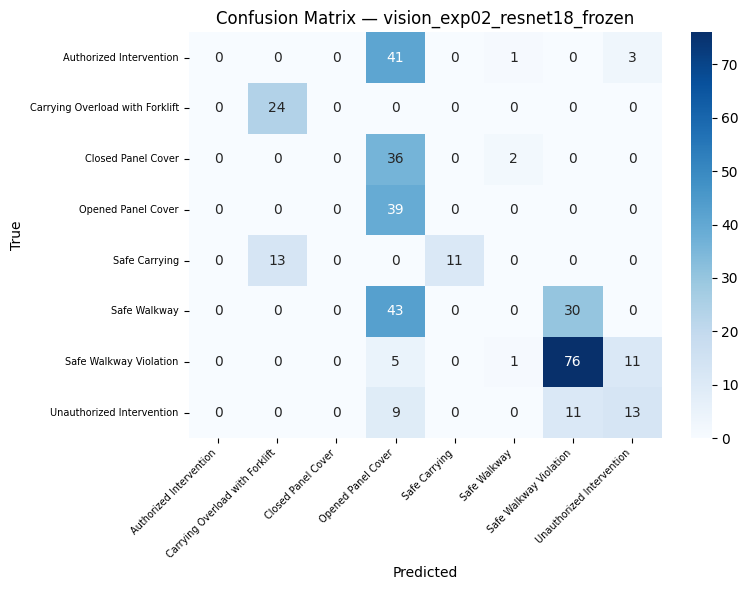

[SAVE] weights → /content/drive/MyDrive/SAMS/models/vision/vision_exp02_resnet18_frozen/model.pt
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vision/vision_exp02_resnet18_frozen/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vision/vision_experiment_ledger.csv
[GC] memory freed


In [36]:
exp_id = "vision_exp02_resnet18_frozen"
approach = "Transfer learning — ResNet18 (frozen backbone)"

model = build_resnet18(NUM_CLASSES, freeze_backbone=True)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_TRANSFER,
    lr=1e-3,
)
save_experiment(model, result, extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": True})
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None


### Experiment 3 — ResNet18 fine-tuning
**Approach:** unfreeze full ResNet18 and fine-tune with a lower learning rate.


EXPERIMENT: vision_exp03_resnet18_finetune
APPROACH:   Fine-tuning — ResNet18 (full network, lower LR)
Epochs=8  LR=3e-05  Device=cuda


[vision_exp03_resnet18_finetune] epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.3068 | val_loss=1.0213 | val_acc=0.6468 | val_f1_macro=0.4902


[vision_exp03_resnet18_finetune] epoch 2/8:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError: can only test a child process<function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

[vision_exp03_resnet18_finetune] epoch 7/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 07 | train_loss=0.5111 | val_loss=0.7272 | val_acc=0.7222 | val_f1_macro=0.6335


[vision_exp03_resnet18_finetune] epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 08 | train_loss=0.4716 | val_loss=0.7268 | val_acc=0.7222 | val_f1_macro=0.6304

--- Test metrics ---
Accuracy:          0.6125
Precision (macro): 0.6830
Recall (macro):    0.6761
F1 (macro):        0.6419
F1 (weighted):     0.5941
                                 precision    recall  f1-score   support

        Authorized Intervention       0.83      0.22      0.35        45
Carrying Overload with Forklift       1.00      1.00      1.00        24
             Closed Panel Cover       0.55      0.82      0.66        38
             Opened Panel Cover       0.42      0.79      0.55        39
                  Safe Carrying       1.00      1.00      1.00        24
                   Safe Walkway       0.54      0.30      0.39        73
         Safe Walkway Violation       0.68      0.70      0.69        93
      Unauthorized Intervention       0.43      0.58      0.49        33

                       accuracy                           0.61       369
                      macro 

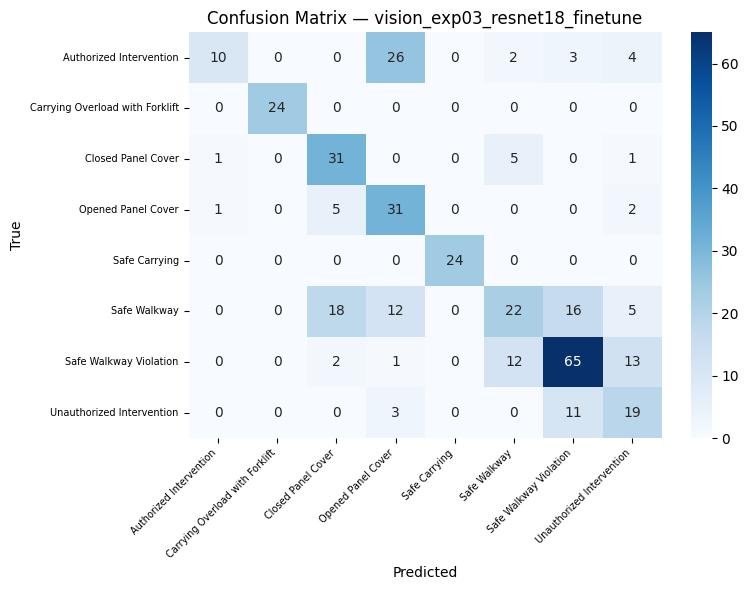

[SAVE] weights → /content/drive/MyDrive/SAMS/models/vision/vision_exp03_resnet18_finetune/model.pt
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vision/vision_exp03_resnet18_finetune/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vision/vision_experiment_ledger.csv
[GC] memory freed


In [37]:
exp_id = "vision_exp03_resnet18_finetune"
approach = "Fine-tuning — ResNet18 (full network, lower LR)"

model = build_resnet18(NUM_CLASSES, freeze_backbone=False)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_FINETUNE,
    lr=3e-5,
)
save_experiment(model, result, extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": False})
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None


### Experiment 4 — EfficientNet-B0 transfer learning
**Approach:** EfficientNet-B0 with frozen backbone — stronger feature extractor than ResNet18.


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 159MB/s]

EXPERIMENT: vision_exp04_efficientnet_b0_frozen
APPROACH:   Transfer learning — EfficientNet-B0 (frozen backbone)
Epochs=6  LR=0.001  Device=cuda


[vision_exp04_efficientnet_b0_frozen] epoch 1/6:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.3642 | val_loss=1.0657 | val_acc=0.5794 | val_f1_macro=0.2802


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 05 | train_loss=0.8922 | val_loss=0.9031 | val_acc=0.6230 | val_f1_macro=0.4605


[vision_exp04_efficientnet_b0_frozen] epoch 6/6:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 06 | train_loss=0.8717 | val_loss=0.8984 | val_acc=0.6310 | val_f1_macro=0.4734

--- Test metrics ---
Accuracy:          0.4905
Precision (macro): 0.5228
Recall (macro):    0.5298
F1 (macro):        0.4606
F1 (weighted):     0.4137
                                 precision    recall  f1-score   support

        Authorized Intervention       0.00      0.00      0.00        45
Carrying Overload with Forklift       0.89      1.00      0.94        24
             Closed Panel Cover       1.00      0.21      0.35        38
             Opened Panel Cover       0.23      1.00      0.38        39
                  Safe Carrying       1.00      0.88      0.93        24
                   Safe Walkway       0.00      0.00      0.00        73
         Safe Walkway Violation       0.64      0.85      0.73        93
      Unauthorized Intervention       0.42      0.30      0.35        33

                       accuracy                           0.49       369
                      macro 

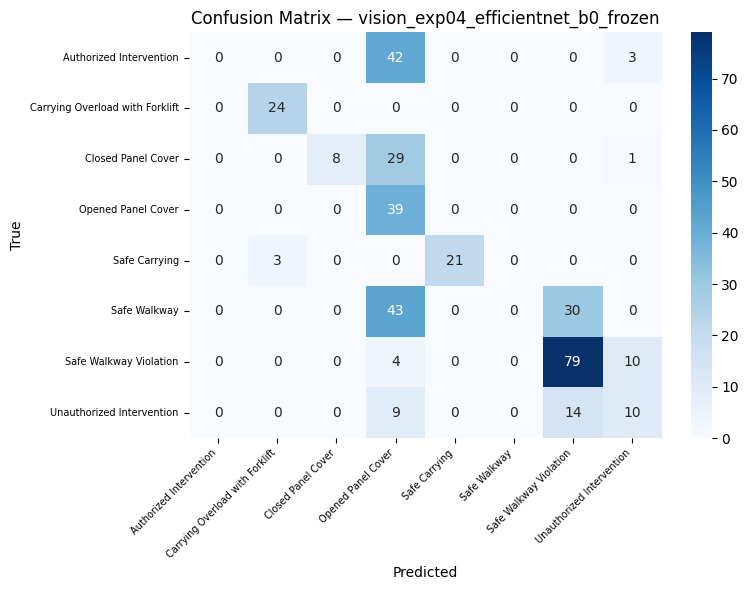

[SAVE] weights → /content/drive/MyDrive/SAMS/models/vision/vision_exp04_efficientnet_b0_frozen/model.pt
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vision/vision_exp04_efficientnet_b0_frozen/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vision/vision_experiment_ledger.csv
[GC] memory freed


In [38]:
exp_id = "vision_exp04_efficientnet_b0_frozen"
approach = "Transfer learning — EfficientNet-B0 (frozen backbone)"

model = build_efficientnet_b0(NUM_CLASSES, freeze_backbone=True)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_EFFICIENT,
    lr=1e-3,
)
save_experiment(
    model, result,
    extra_meta={"architecture": "EfficientNet-B0", "pretrained": True, "freeze_backbone": True},
)
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None


### Experiment 5 — MobileNetV3-Small (edge / SAMS deployment)
**Approach:** lightweight MobileNetV3-Small for on-device / low-latency SAMS inference.


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 112MB/s]

EXPERIMENT: vision_exp05_mobilenet_v3_small
APPROACH:   Edge-friendly — MobileNetV3-Small (frozen backbone)
Epochs=6  LR=0.001  Device=cuda


[vision_exp05_mobilenet_v3_small] epoch 1/6:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.2643 | val_loss=1.3795 | val_acc=0.5714 | val_f1_macro=0.2896


...

[vision_exp05_mobilenet_v3_small] epoch 5/6:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 05 | train_loss=0.8085 | val_loss=0.8853 | val_acc=0.6508 | val_f1_macro=0.4820


[vision_exp05_mobilenet_v3_small] epoch 6/6:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Exception ignored in: if w.is_alive():<function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()

AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
:     can only test a child processif w.is_alive():

  File "/usr/lib/

  epoch 06 | train_loss=0.8008 | val_loss=0.8620 | val_acc=0.6548 | val_f1_macro=0.4997

--- Test metrics ---
Accuracy:          0.5095
Precision (macro): 0.5052
Recall (macro):    0.5541
F1 (macro):        0.4847
F1 (weighted):     0.4306
                                 precision    recall  f1-score   support

        Authorized Intervention       0.00      0.00      0.00        45
Carrying Overload with Forklift       1.00      1.00      1.00        24
             Closed Panel Cover       0.79      0.29      0.42        38
             Opened Panel Cover       0.25      1.00      0.40        39
                  Safe Carrying       1.00      1.00      1.00        24
                   Safe Walkway       0.00      0.00      0.00        73
         Safe Walkway Violation       0.64      0.87      0.74        93
      Unauthorized Intervention       0.36      0.27      0.31        33

                       accuracy                           0.51       369
                      macro 

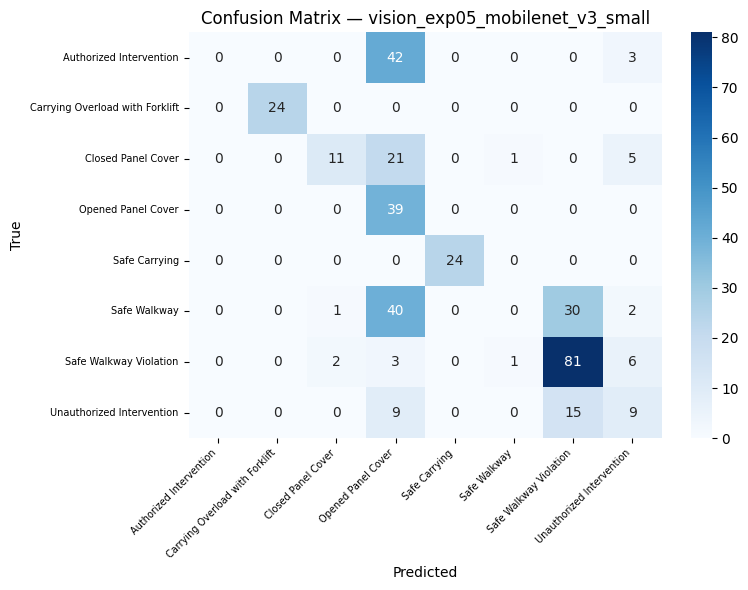

[SAVE] weights → /content/drive/MyDrive/SAMS/models/vision/vision_exp05_mobilenet_v3_small/model.pt
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vision/vision_exp05_mobilenet_v3_small/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vision/vision_experiment_ledger.csv
[GC] memory freed


In [39]:
exp_id = "vision_exp05_mobilenet_v3_small"
approach = "Edge-friendly — MobileNetV3-Small (frozen backbone)"

model = build_mobilenet_v3_small(NUM_CLASSES, freeze_backbone=True)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_MOBILE,
    lr=1e-3,
)
save_experiment(
    model, result,
    extra_meta={"architecture": "MobileNetV3-Small", "pretrained": True, "freeze_backbone": True, "deployment": "edge"},
)
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None


### Experiment 6 — Robust EfficientNet (class weights + strong augmentation)
**Approach:** EfficientNet-B0 fine-tuned with **class-weighted loss**, **strong augmentation**, and a **weighted sampler** to handle imbalance.


Class weights: {'Authorized Intervention': np.float32(1.5132), 'Carrying Overload with Forklift': np.float32(0.7451), 'Closed Panel Cover': np.float32(2.1857), 'Opened Panel Cover': np.float32(0.2851), 'Safe Carrying': np.float32(1.8214), 'Safe Walkway': np.float32(0.8129), 'Safe Walkway Violation': np.float32(0.2251), 'Unauthorized Intervention': np.float32(0.4115)}
EXPERIMENT: vision_exp06_efficientnet_robust
APPROACH:   Robust training — EfficientNet-B0 fine-tune + class weights + strong aug + weighted sampler
Epochs=8  LR=3e-05  Device=cuda


[vision_exp06_efficientnet_robust] epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.8410 | val_loss=2.1203 | val_acc=0.1548 | val_f1_macro=0.1460


[vision_exp06_efficientnet_robust] epoch 2/8:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 07 | train_loss=0.9917 | val_loss=1.9862 | val_acc=0.2222 | val_f1_macro=0.3471


[vision_exp06_efficientnet_robust] epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7808a457f560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 08 | train_loss=1.0037 | val_loss=1.9915 | val_acc=0.2222 | val_f1_macro=0.3432

--- Test metrics ---
Accuracy:          0.3713
Precision (macro): 0.3951
Recall (macro):    0.4553
F1 (macro):        0.3696
F1 (weighted):     0.2927
                                 precision    recall  f1-score   support

        Authorized Intervention       0.60      0.64      0.62        45
Carrying Overload with Forklift       1.00      0.38      0.55        24
             Closed Panel Cover       0.28      1.00      0.43        38
             Opened Panel Cover       0.00      0.00      0.00        39
                  Safe Carrying       0.62      1.00      0.76        24
                   Safe Walkway       0.25      0.41      0.31        73
         Safe Walkway Violation       0.00      0.00      0.00        93
      Unauthorized Intervention       0.41      0.21      0.28        33

                       accuracy                           0.37       369
                      macro 

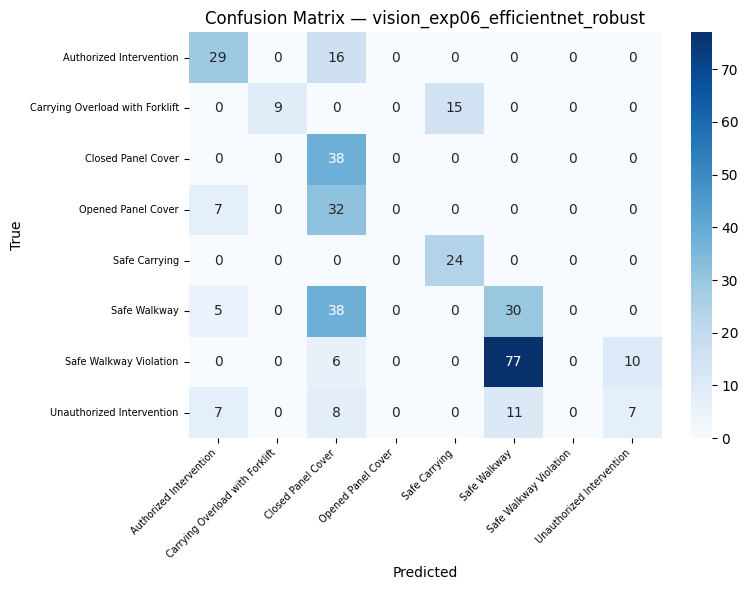

[SAVE] weights → /content/drive/MyDrive/SAMS/models/vision/vision_exp06_efficientnet_robust/model.pt
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/vision/vision_exp06_efficientnet_robust/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/vision/vision_experiment_ledger.csv
[GC] memory freed


In [40]:
exp_id = "vision_exp06_efficientnet_robust"
approach = "Robust training — EfficientNet-B0 fine-tune + class weights + strong aug + weighted sampler"

robust_loaders = make_loaders(
    frame_manifest,
    train_transform=strong_train_tfms,
    use_weighted_sampler=True,
)

# Inverse-frequency class weights from train split
train_counts = robust_loaders["train_df"]["label_idx"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
weights = (1.0 / train_counts.clip(lower=1)).values.astype(np.float32)
weights = weights / weights.sum() * NUM_CLASSES
class_weights = torch.tensor(weights, dtype=torch.float32)
print("Class weights:", dict(zip(CLASS_NAMES, weights.round(4))))

model = build_efficientnet_b0(NUM_CLASSES, freeze_backbone=False)
model, result = train_one_experiment(
    model,
    robust_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_ROBUST,
    lr=3e-5,
    class_weights=class_weights,
)
save_experiment(
    model, result,
    extra_meta={
        "architecture": "EfficientNet-B0",
        "pretrained": True,
        "freeze_backbone": False,
        "class_weights": weights.tolist(),
        "strong_augmentation": True,
        "weighted_sampler": True,
    },
)
EXPERIMENT_RESULTS.append(result)

free_memory(model, robust_loaders)
model = None
result = None
robust_loaders = None


## 7. Proper comparison — Accuracy, Precision, Recall, F1

Aggregate all experiment metrics, rank by **F1-macro** (primary for multiclass safety labels),
and pick a recommended vision backbone for SAMS.


In [41]:
# Prefer ledger on Drive (survives re-runs / partial sessions)
ledger_path = RESULTS_DIR / "vision_experiment_ledger.csv"
if ledger_path.exists():
    comparison_df = pd.read_csv(ledger_path)
else:
    comparison_df = pd.DataFrame([
        {
            "experiment_id": r["experiment_id"],
            "approach": r["approach"],
            "accuracy": r["test_metrics"]["accuracy"],
            "precision_macro": r["test_metrics"]["precision_macro"],
            "recall_macro": r["test_metrics"]["recall_macro"],
            "f1_macro": r["test_metrics"]["f1_macro"],
            "f1_weighted": r["test_metrics"]["f1_weighted"],
            "best_val_f1_macro": r["best_val_f1_macro"],
            "epochs": r["epochs"],
            "elapsed_sec": r["elapsed_sec"],
        }
        for r in EXPERIMENT_RESULTS
    ])

comparison_df = comparison_df.sort_values("f1_macro", ascending=False).reset_index(drop=True)
comparison_path = RESULTS_DIR / "vision_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("=== SAMS Vision Model Comparison (sorted by F1-macro) ===")
display_cols = [
    "experiment_id", "approach", "accuracy",
    "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
]
print(comparison_df[display_cols].to_string(index=False))
print("\nSaved:", comparison_path)

best = comparison_df.iloc[0]
print("\n★ Best experiment:", best["experiment_id"])
print("  Approach:", best["approach"])
print("  Accuracy:", round(best["accuracy"], 4))
print("  F1-macro:", round(best["f1_macro"], 4))
print("  F1-weighted:", round(best["f1_weighted"], 4))


=== SAMS Vision Model Comparison (sorted by F1-macro) ===
                      experiment_id                                                                                    approach  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted
     vision_exp03_resnet18_finetune                                             Fine-tuning — ResNet18 (full network, lower LR)  0.612466         0.683022      0.676117  0.641873     0.594071
    vision_exp05_mobilenet_v3_small                                         Edge-friendly — MobileNetV3-Small (frozen backbone)  0.509485         0.505227      0.554146  0.484662     0.430554
vision_exp04_efficientnet_b0_frozen                                       Transfer learning — EfficientNet-B0 (frozen backbone)  0.490515         0.522846      0.529752  0.460648     0.413689
   vision_exp06_efficientnet_robust Robust training — EfficientNet-B0 fine-tune + class weights + strong aug + weighted sampler  0.371274         0.395114      0.455316  0.36

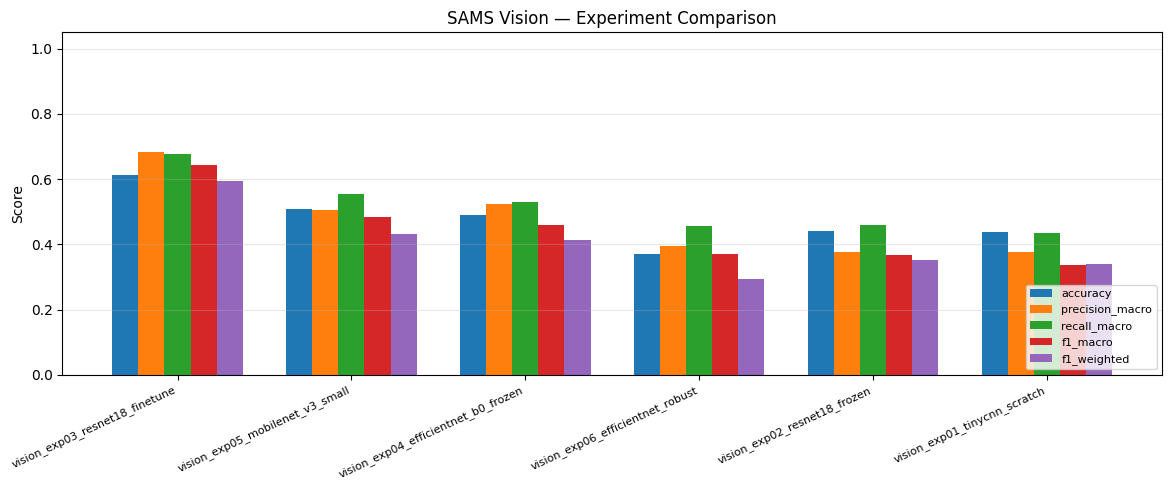

Saved chart: /content/drive/MyDrive/SAMS/results/vision/vision_comparison_bars.png


In [42]:
# --- Comparison charts -------------------------------------------------------
plot_df = comparison_df.copy()
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted"]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(plot_df))
width = 0.15
for i, m in enumerate(metrics):
    ax.bar(x + i * width, plot_df[m], width, label=m)
ax.set_xticks(x + width * 2)
ax.set_xticklabels(plot_df["experiment_id"], rotation=25, ha="right", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("SAMS Vision — Experiment Comparison")
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig_path = RESULTS_DIR / "vision_comparison_bars.png"
plt.savefig(fig_path, dpi=150)
plt.show()
print("Saved chart:", fig_path)


In [43]:
# --- Write a short comparison summary JSON for the SAMS app later ------------
summary = {
    "task": "vision_safe_unsafe_behaviours",
    "dataset": HF_REPO,
    "num_experiments": int(len(comparison_df)),
    "primary_metric": "f1_macro",
    "best_experiment_id": str(best["experiment_id"]),
    "best_approach": str(best["approach"]),
    "best_metrics": {
        "accuracy": float(best["accuracy"]),
        "precision_macro": float(best["precision_macro"]),
        "recall_macro": float(best["recall_macro"]),
        "f1_macro": float(best["f1_macro"]),
        "f1_weighted": float(best["f1_weighted"]),
    },
    "all_experiments": comparison_df[display_cols].to_dict(orient="records"),
    "models_dir": str(MODELS_DIR),
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
}
summary_path = RESULTS_DIR / "vision_comparison_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)
print("Summary:", summary_path)
print(json.dumps(summary["best_metrics"], indent=2))


Summary: /content/drive/MyDrive/SAMS/results/vision/vision_comparison_summary.json
{
  "accuracy": 0.6124661246612466,
  "precision_macro": 0.683022046267371,
  "recall_macro": 0.6761169575915372,
  "f1_macro": 0.6418729821410393,
  "f1_weighted": 0.5940711455453488
}


In [44]:
# Final cleanup of large training objects (optional)
free_memory(base_loaders)
base_loaders = None
print("Done. Vision experiment suite finished.")
print("Models:", MODELS_DIR)
print("Results:", RESULTS_DIR)


[GC] memory freed
Done. Vision experiment suite finished.
Models: /content/drive/MyDrive/SAMS/models/vision
Results: /content/drive/MyDrive/SAMS/results/vision
